In [19]:
import numpy as np
import pandas as pd
import random

def wiener_step(mu, sigma, dt=1.0):
    """单步Wiener过程变化"""
    return mu * dt + sigma * np.sqrt(dt) * np.random.randn()

def generate_maintenance_plan_wiener(N, T, random_seed, alpha_range=(-0.01, -0.001), 
                                   sigma_range=(0.02, 0.05), initial_p_range=(3.2, 3.5)):
    """
    Wiener过程版本：非线性随机退化维护计划
    新增：sigma_range波动参数
    """
    caissons = list(range(N))
    
    random.seed(random_seed)
    np.random.seed(random_seed)
    alpha_values = np.round(np.random.uniform(*alpha_range, N), 6)  # mu=alpha
    
    random.seed(random_seed + 1)
    np.random.seed(random_seed + 1)
    sigma_values = np.round(np.random.uniform(*sigma_range, N), 6)
    initial_p_values = np.round(np.random.uniform(*initial_p_range, N), 2)
    
    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []
    index = 0
    
    for caisson in caissons:
        current_p = initial_p_values[caisson]
        total_days = 0
        mu = alpha_values[caisson]
        sigma = sigma_values[caisson]
        
        while total_days < T:
            # Wiener路径模拟直到击中3.2
            p = current_p
            day = 0
            while p > 3.2 and total_days + day < T:
                p += wiener_step(mu, sigma)
                day += 1
            
            time_to_3_2 = day
            if total_days + time_to_3_2 >= T:
                break
            
            data.append([index, caisson, initial_p_values[caisson], 'x', total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1  # +1停机日
            current_p = 3.5  # 重置
    
    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values, sigma_values


# 生成3台设备，10年(3650天)计划，种子42确保重复
plan, alphas, sigmas = generate_maintenance_plan_wiener(
    N=100,                    # 设备数
    T=180,                 # 总天数
    random_seed=42,         # 固定种子
    alpha_range=(-0.01, -0.001),  # 退化速率范围
    sigma_range=(0.02, 0.05),# 波动范围
    initial_p_range=(3.2, 3.5)  # 初始压力
)

print(plan)  # DataFrame查看计划
print("退化参数:", alphas)  # mu列表
print("波动参数:", sigmas)  # sigma列表

     INDEX  CSEM  INITIALP OPERATION  DATE
0        0     0      3.23         x     8
1        1     0      3.23         x   109
2        2     0      3.23         x   133
3        3     0      3.23         x   167
4        4     1      3.35         x    67
..     ...   ...       ...       ...   ...
351    351    98      3.23         x   151
352    352    99      3.49         x    10
353    353    99      3.49         x    47
354    354    99      3.49         x   120
355    355    99      3.49         x   173

[356 rows x 5 columns]
退化参数: [-0.006629 -0.001444 -0.003412 -0.004612 -0.008596 -0.008596 -0.009477
 -0.002204 -0.00459  -0.003627 -0.009815 -0.001271 -0.002508 -0.008089
 -0.008364 -0.008349 -0.007262 -0.005277 -0.006112 -0.007379 -0.004493
 -0.008745 -0.007371 -0.006703 -0.005895 -0.002933 -0.008203 -0.005372
 -0.004668 -0.009582 -0.004532 -0.008465 -0.009415 -0.00146  -0.001309
 -0.002724 -0.007258 -0.009121 -0.003842 -0.006039 -0.008902 -0.005543
 -0.009691 -0.001816 -0.0076

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_17403/3315162896.py:15: UserWarning: Glyph 35745 (\N{CJK UNIFIED IDEOGRAPH-8BA1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_17403/3315162896.py:15: UserWarning: Glyph 21010 (\N{CJK UNIFIED IDEOGRAPH-5212}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_17403/3315162896.py:15: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_17403/3315162896.py:15: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_17403/3315162896.py:15: UserWarning: Glyph 22825 (\N{CJK UNIFIED IDEOGRAPH-5929}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/08/0s62

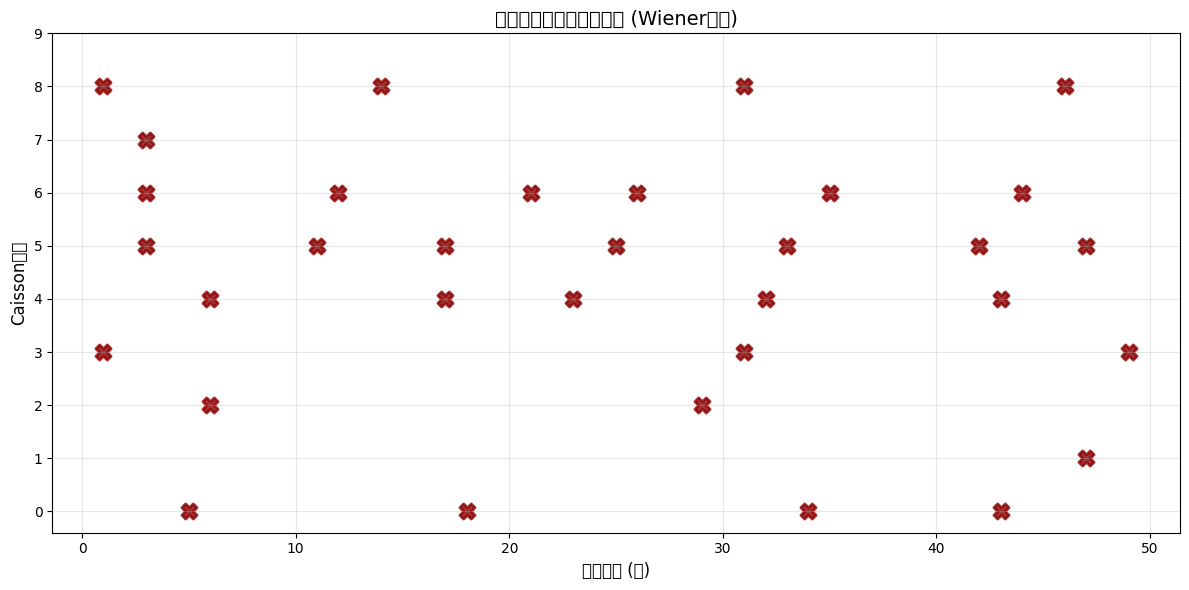

In [20]:
import matplotlib.pyplot as plt

# 假设您已生成plan（用负alpha_range）
plan, alphas, sigmas = generate_maintenance_plan_wiener(
    N=10, T=50, random_seed=42, alpha_range=(-0.05, -0.001)
)

plt.figure(figsize=(12, 6))
plt.scatter(plan['DATE'], plan['CSEM'], c='darkred', s=120, marker='X', linewidth=2, alpha=0.8)
plt.xlabel('计划时间 (天)', fontsize=12)
plt.ylabel('Caisson编号', fontsize=12)
plt.title('气体管道维护计划散点图 (Wiener退化)', fontsize=14)
plt.grid(True, alpha=0.3)
plt.yticks(range(10))  # 清晰显示0-9编号
plt.tight_layout()
plt.show()  # 或 plt.savefig('plan.png', dpi=300)
